In [2]:
import os
import subprocess
import numpy as np
import pandas as pd
import pandas_gbq

my_bucket = "gs://rw-migration-aou-rw-67cadd48"
current_directory = "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"

project_id = os.environ.get('GOOGLE_CLOUD_PROJECT')
print(project_id)

dataset_id='C2024Q3R9'

dataset=!wb resolve --id {dataset_id} 
dataset_str = dataset[0]
print(dataset_str)
workspace_bucket = f"gs://cloned-mybucket{project_id}"
os.environ["WORKSPACE_BUCKET"] = workspace_bucket

# Set environment variable
os.environ['WORKSPACE_CDR'] = dataset_str
CDR_version = os.getenv("WORKSPACE_CDR")
dataset = %env WORKSPACE_CDR

wb-chirpy-leek-1262
wb-silky-artichoke-2408.C2024Q3R9


# Load in Data

## Individual-level SES

In [3]:
demographics_file = f"{current_directory}/data/all_WGS_demographics.csv"

# Read CSV and select only desired columns
ses = pd.read_csv(
    demographics_file,
    usecols=["person_id", "income", "number_living", "education", "basics_survey_datetime"]
)


# Clean and format datetime

# Ensure is in datetime format
ses['basics_survey_datetime'] = pd.to_datetime(ses['basics_survey_datetime'], errors='coerce')

# Remove timezone info if present
ses['basics_survey_datetime'] = ses['basics_survey_datetime'].dt.tz_localize(None)

# extract year-month as timestamp
# was in format 2019-05-18 00:16:27 but just need 2019-05-18
ses['survey_datetime'] = ses['basics_survey_datetime'].dt.to_period('M').dt.to_timestamp()

# Drop the original column
ses = ses.drop(columns=['basics_survey_datetime'])

#Drop those without education data
ses = ses[ses['education'] != 'Skip or PNA']

#Comvert Education to semi-continous numeric
# Define mapping for the semi-continuous 5-level education variable
education_mapping = {
    "Less than high school degree or equivalent": 5,
    "Twelve or GED": 4,
    "College One to Three": 3,
    "College graduate": 2,
    "Advanced degree": 1
}

# Apply mapping to create a new numeric column
ses["education"] = ses["education"].map(education_mapping)


# -----------------------------
# Final Format Notes:
# -----------------------------
# Columns: 
# - person_id (int)
# - number_living (int)
# - education (int) 1 (advanced degree) to 5 (less than highschool)
# - income (numeric: 5000, 12500, 30000, 42500, 62500, 87500, 125000, 175000, 225000 or NaN)
# - survey_datetime (datetime object, year-day-month, e.g., 2019-05-18)

ses.info()

<class 'pandas.core.frame.DataFrame'>
Index: 282828 entries, 0 to 289190
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   person_id        282828 non-null  int64         
 1   number_living    275707 non-null  float64       
 2   education        282828 non-null  int64         
 3   income           227969 non-null  float64       
 4   survey_datetime  282828 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(2)
memory usage: 12.9 MB


## Zip Code

In [4]:
import pandas
import os

# This query represents dataset "zip_code_area" for domain "zip_code_socioeconomic" and was generated for All of Us Controlled Tier Dataset v8
dataset_11149684_zip_code_socioeconomic_sql = """
    SELECT
        observation.person_id,
        observation.observation_datetime,
        zip_code.zip3_as_string as zip_code,
        zip_code.fraction_assisted_income as assisted_income,
        zip_code.fraction_high_school_edu as high_school_education,
        zip_code.median_income,
        zip_code.fraction_no_health_ins as no_health_insurance,
        zip_code.fraction_poverty as poverty,
        zip_code.fraction_vacant_housing as vacant_housing,
        zip_code.deprivation_index,
        zip_code.acs as american_community_survey_year 
    FROM
        `""" + os.environ["WORKSPACE_CDR"] + """.zip3_ses_map` zip_code 
    JOIN
        `""" + os.environ["WORKSPACE_CDR"] + """.observation` observation 
            ON CAST(SUBSTR(observation.value_as_string, 0, STRPOS(observation.value_as_string, '*') - 1) AS INT64) = zip_code.zip3 
            AND observation_source_concept_id = 1585250 
            AND observation.value_as_string NOT LIKE 'Res%'"""

zip_code_socioeconomic_df = pandas_gbq.read_gbq(
    dataset_11149684_zip_code_socioeconomic_sql,
    dialect="standard",
    use_bqstorage_api=("BIGQUERY_STORAGE_API_ENABLED" in os.environ),
    progress_bar_type="tqdm_notebook")

zip_code_socioeconomic_df.head(5)
# -----------------------------
# Final Format Notes:
# -----------------------------
# Columns: 
# - person_id (int)
# - observation_datetime (datetime object, e.g., 2019-05-18 00:16:27)
# - zip_code (object, e.g. 353**)

zip_code_socioeconomic_df.info()

zip_code_socioeconomic_df = zip_code_socioeconomic_df.rename(columns={'deprivation_index': 'deprivation_index_socio'})


Downloading:   0%|          |

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 606414 entries, 0 to 606413
Data columns (total 11 columns):
 #   Column                          Non-Null Count   Dtype              
---  ------                          --------------   -----              
 0   person_id                       606414 non-null  Int64              
 1   observation_datetime            606414 non-null  datetime64[us, UTC]
 2   zip_code                        606414 non-null  object             
 3   assisted_income                 606414 non-null  float64            
 4   high_school_education           606414 non-null  float64            
 5   median_income                   606414 non-null  float64            
 6   no_health_insurance             606414 non-null  float64            
 7   poverty                         606414 non-null  float64            
 8   vacant_housing                  606414 non-null  float64            
 9   deprivation_index               606414 non-null  float64            
 

## National Poverty Guidelines

In [7]:
#Provided in Github micah-r-hysong/PRS_SDoH_analysis/poverty_guidelines

files = {
    "https://raw.githubusercontent.com/micah-r-hysong/PRS_SDoH_analysis/main/poverty_guidelines/poverty-guidelines-48-states.csv": "pov_states",
    "https://raw.githubusercontent.com/micah-r-hysong/PRS_SDoH_analysis/main/poverty_guidelines/poverty-guidelines-hawaii.csv": "pov_hawaii",
    "https://raw.githubusercontent.com/micah-r-hysong/PRS_SDoH_analysis/main/poverty_guidelines/poverty-guidelines-alaska.csv": "pov_alaska",
}

for url, var_name in files.items():
    globals()[var_name] = pd.read_csv(url)
    


## ACS Data

In [9]:
#Provided in Github micah-r-hysong/ACS_metrics/ACS_data_2013_2023.csv

acs_file = "https://raw.githubusercontent.com/micah-r-hysong/PRS_SDoH_analysis/main/ACS_metrics/ACS_data_2013_2023.csv"


# Read CSV 
acs_data = pd.read_csv(
    acs_file)

acs_data = acs_data.rename(columns={'fraction_high_school_edu': 'fraction_no_high_school_education'})
acs_data = acs_data.rename(columns={'median_income': 'lower_median_income'})

# Make Percent of Poverty Threshold Score

In [10]:
# --- Clean and format date columns (handles mixed formats safely) ---
for df in [pov_states, pov_hawaii, pov_alaska]:
    df['Date of Publication'] = pd.to_datetime(
        df['Date of Publication'],
        format='mixed',   # allows mixed date styles, e.g. 'Jan-72' and 'January 2020'
        errors='coerce'   # convert invalid formats to NaT
    )
    df['Date of Publication'] = df['Date of Publication'].dt.tz_localize(None)


In [11]:
# Function to assign location based on zip_code
def assign_location(zip_code):
    if zip_code.startswith('995'):
        return 'alaska'
    elif zip_code.startswith('967'):
        return 'hawaii'
    else:
        return 'states'

# Apply the function to create the location column
zip_code_socioeconomic_df['location'] = zip_code_socioeconomic_df['zip_code'].apply(assign_location)

# Create new DataFrame with person_id and location columns
demo_df = zip_code_socioeconomic_df[['person_id', 'location']]

#Add in ses
demo_df = pd.merge(demo_df, ses, on="person_id")

print(demo_df['location'].value_counts())

demo_df.info()

location
states    271658
hawaii        52
alaska        10
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271720 entries, 0 to 271719
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   person_id        271720 non-null  Int64         
 1   location         271720 non-null  object        
 2   number_living    265014 non-null  float64       
 3   education        271720 non-null  int64         
 4   income           219215 non-null  float64       
 5   survey_datetime  271720 non-null  datetime64[ns]
dtypes: Int64(1), datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 12.7+ MB


In [12]:
# Function to find the closest date in pov_df and calculate the distance in months
def find_closest_date_and_distance(demo_date, pov_df):
    pov_df['date_diff'] = (pov_df['Date of Publication'] - demo_date).abs()
    closest_row = pov_df.loc[pov_df['date_diff'].idxmin()]
    distance_in_months = (closest_row['Date of Publication'].year - demo_date.year) * 12 + (closest_row['Date of Publication'].month - demo_date.month)
    distance_in_months = abs(distance_in_months)
    return closest_row, distance_in_months

# Function to merge demo_df with the closest date in pov_df and calculate the poverty threshold
def merge_and_calculate_threshold(demo, pov):
    merged_rows = []
    for _, demo_row in demo.iterrows():
        closest_pov_row, distance_in_months = find_closest_date_and_distance(demo_row['survey_datetime'], pov)
        merged_row = pd.concat([demo_row, closest_pov_row])
        merged_row['distance_in_months'] = distance_in_months
        merged_rows.append(merged_row)
    merged_df = pd.DataFrame(merged_rows)
    
    # Calculate poverty threshold
    def get_poverty_threshold(row):
        if row['number_living'] == 1:
            return row['1 Person']
        elif row['number_living'] == 2:
            return row['2 Persons']
        elif row['number_living'] == 3:
            return row['3 Persons']
        elif row['number_living'] == 4:
            return row['4 Persons']
        elif row['number_living'] == 5:
            return row['5 Persons']
        elif row['number_living'] == 6:
            return row['6 Persons']
        elif row['number_living'] == 7:
            return row['7 Persons']
        elif row['number_living'] == 8:
            return row['8 Persons']
        else:
            return row['8 Persons'] + (row['number_living'] - 8) * row['$ For Each Additional Person (9+)']
    
    merged_df['poverty_threshold'] = merged_df.apply(get_poverty_threshold, axis=1)
    return merged_df

# Separate demo_df into states and hawaii DataFrames
demo_states = demo_df[demo_df['location'] == 'states']
demo_hawaii = demo_df[demo_df['location'] == 'hawaii']
demo_alaska = demo_df[demo_df['location'] == 'alaska']

# Merge with the respective poverty data
print(demo_states.shape[0])
merged_states = merge_and_calculate_threshold(demo_states, pov_states)
print(merged_states.shape[0])

print(demo_hawaii.shape[0])
merged_hawaii = merge_and_calculate_threshold(demo_hawaii, pov_hawaii)
print(merged_hawaii.shape[0])

print(demo_alaska.shape[0])
merged_alaska = merge_and_calculate_threshold(demo_alaska, pov_alaska)
print(merged_alaska.shape[0])

# Combine the two DataFrames
final_df = pd.concat([merged_states, merged_hawaii, merged_alaska])

# Select the relevant columns to form the final DataFrame
final_df = final_df[['person_id', 'income', 'number_living', 'education', 'survey_datetime', 'poverty_threshold', 'distance_in_months']]

final_df.info()

271658
271658
52
52
10
10
<class 'pandas.core.frame.DataFrame'>
Index: 271720 entries, 0 to 9
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   person_id           271720 non-null  int64         
 1   income              219215 non-null  float64       
 2   number_living       265014 non-null  float64       
 3   education           271720 non-null  int64         
 4   survey_datetime     271720 non-null  datetime64[ns]
 5   poverty_threshold   265014 non-null  float64       
 6   distance_in_months  271720 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(3)
memory usage: 16.6 MB


<Axes: >

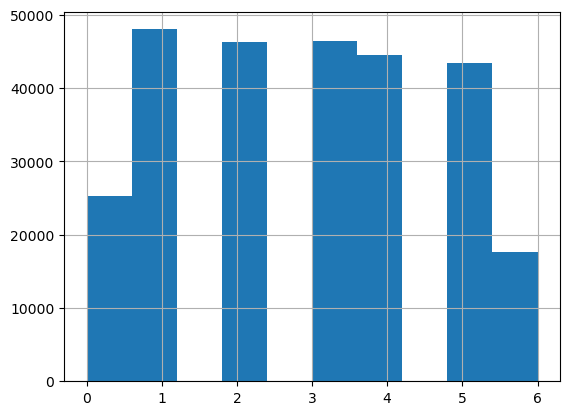

In [13]:
#Make sure our survey datetime and poverty guidelines are close enough in time
final_df['distance_in_months'].hist()

<Axes: >

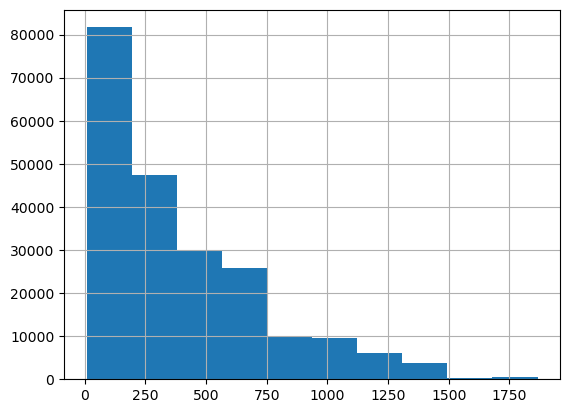

In [14]:
#Make actual percent of poverty score

final_df['per_poverty_threshold']=final_df['income']/final_df['poverty_threshold']*100
final_df['per_poverty_threshold'].hist()

In [15]:
max_val = final_df['per_poverty_threshold'].max()
final_df['individual_poverty'] = max_val - final_df['per_poverty_threshold']

In [16]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 271720 entries, 0 to 9
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   person_id              271720 non-null  int64         
 1   income                 219215 non-null  float64       
 2   number_living          265014 non-null  float64       
 3   education              271720 non-null  int64         
 4   survey_datetime        271720 non-null  datetime64[ns]
 5   poverty_threshold      265014 non-null  float64       
 6   distance_in_months     271720 non-null  int64         
 7   per_poverty_threshold  215029 non-null  float64       
 8   individual_poverty     215029 non-null  float64       
dtypes: datetime64[ns](1), float64(5), int64(3)
memory usage: 20.7 MB


# Get area-level Data

In [17]:
# Ensure zip codes are strings
zip_code_socioeconomic_df['zip_code'] = zip_code_socioeconomic_df['zip_code'].astype(str)
zip_code_socioeconomic_df['zip_prefix'] = zip_code_socioeconomic_df['zip_code'].str[:3].str.zfill(3)

# Extract the first three digits from both for matching
acs_data['zip_prefix'] = acs_data['zip3'].astype(str)
acs_data['zip_prefix'] = acs_data['zip_prefix'].str[:3].str.zfill(3)

# --- Extract observation year ---
zip_code_socioeconomic_df['obs_year'] = zip_code_socioeconomic_df['observation_datetime'].dt.year

print("Start:", zip_code_socioeconomic_df['person_id'].nunique())

# --- Merge on zip prefix to get all potential matches ---
merged = pd.merge(
    zip_code_socioeconomic_df,
    acs_data,
    on='zip_prefix',
    how='left',
    suffixes=('_socio', '_acs')
)

print("After merge:", merged['person_id'].nunique())


# --- Compute year difference and select closest ACS year for each person_id ---
merged['year_diff'] = abs(merged['obs_year'] - merged['year'])

# --- Drop rows where year_diff is NaN (no valid ACS year match) ---
merged = merged.dropna(subset=['year_diff'])

print("After dropna:", merged.dropna(subset=['year_diff'])['person_id'].nunique())


# --- Select closest ACS year for each person_id ---
idx = merged.groupby('person_id')['year_diff'].idxmin()
merged_closest = (
    merged.loc[idx]
    .reset_index(drop=True)
)


Start: 606414
After merge: 606414
After dropna: 603264


<Axes: >

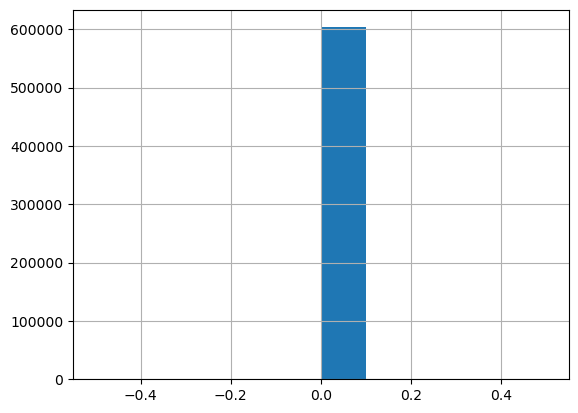

In [18]:
#Make sure our survey datetime and acs info are close enough in time
merged_closest['year_diff'].hist()

In [19]:
merged_closest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 603264 entries, 0 to 603263
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype              
---  ------                             --------------   -----              
 0   person_id                          603264 non-null  Int64              
 1   observation_datetime               603264 non-null  datetime64[us, UTC]
 2   zip_code                           603264 non-null  object             
 3   assisted_income                    603264 non-null  float64            
 4   high_school_education              603264 non-null  float64            
 5   median_income                      603264 non-null  float64            
 6   no_health_insurance                603264 non-null  float64            
 7   poverty                            603264 non-null  float64            
 8   vacant_housing                     603264 non-null  float64            
 9   deprivation_index_socio            60

## Compare AoU ZIP data and ACS data

In [20]:
print(merged_closest[['assisted_income', 'fraction_assisted_income']].corr())
print(merged_closest[['high_school_education', 'fraction_no_high_school_education']].corr())
print(merged_closest[['median_income', 'lower_median_income']].corr())
print(merged_closest[['no_health_insurance', 'fraction_no_health_insurance']].corr())
print(merged_closest[['poverty', 'fraction_poverty']].corr())
print(merged_closest[['vacant_housing', 'fraction_vacant_housing']].corr())
print(merged_closest[['deprivation_index_socio', 'deprivation_index']].corr())

                          assisted_income  fraction_assisted_income
assisted_income                  1.000000                  0.967618
fraction_assisted_income         0.967618                  1.000000
                                   high_school_education  \
high_school_education                            1.00000   
fraction_no_high_school_education               -0.98281   

                                   fraction_no_high_school_education  
high_school_education                                       -0.98281  
fraction_no_high_school_education                            1.00000  
                     median_income  lower_median_income
median_income             1.000000            -0.915163
lower_median_income      -0.915163             1.000000
                              no_health_insurance  \
no_health_insurance                      1.000000   
fraction_no_health_insurance             0.962726   

                              fraction_no_health_insurance  
no_health_ins

# Make Final SES dataframe

In [21]:
# Drop unnecessary columns
merged_closest = merged_closest.drop(
    columns=['observation_datetime', 'zip_code', 'location', 'zip_prefix', 
             'obs_year', 'zip3', 'year', 'year_diff',
            'assisted_income', 'high_school_education', 'median_income', 'no_health_insurance',
            'poverty', 'vacant_housing', 'deprivation_index_socio'],
    errors='ignore'  # prevents error if a column is missing
)

final_df = final_df.drop(
    columns = ['distance_in_months', 'number_living', 'survey_datetime', 'poverty_threshold'],
    errors='ignore'  # prevents error if a column is missing
)

# Merge with final_df on person_id
final_merged = pd.merge(
    final_df,
    merged_closest,
    on='person_id',
    how='inner'
)

final_merged = final_merged.dropna()


final_merged.info()

<class 'pandas.core.frame.DataFrame'>
Index: 214915 entries, 0 to 271600
Data columns (total 13 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   person_id                          214915 non-null  int64  
 1   income                             214915 non-null  float64
 2   education                          214915 non-null  int64  
 3   per_poverty_threshold              214915 non-null  float64
 4   individual_poverty                 214915 non-null  float64
 5   american_community_survey_year     214915 non-null  Int64  
 6   fraction_assisted_income           214915 non-null  float64
 7   fraction_no_high_school_education  214915 non-null  float64
 8   lower_median_income                214915 non-null  float64
 9   fraction_no_health_insurance       214915 non-null  float64
 10  fraction_poverty                   214915 non-null  float64
 11  fraction_vacant_housing            214915 no

In [22]:
#Save file
final_merged.to_csv('SES_data.csv', index=False)
args = ["gsutil", "cp", f"./SES_data.csv", f"{my_bucket}/data/"]
output = subprocess.run(args, capture_output=True)